# KDD: Mall Customer Segmentation

## Select
The dataset contains customer income and spending score. The goal is to discover useful customer groups without a predefined target.

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
url='https://raw.githubusercontent.com/hannazan/mall-customer-segmentation/main/data/Mall_Customers.csv'
df=pd.read_csv(url); print(df.shape); display(df.head())

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Preprocess
Check missing values and duplicates, normalize column names, and select the two numerical behavioral attributes.

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicates: 0


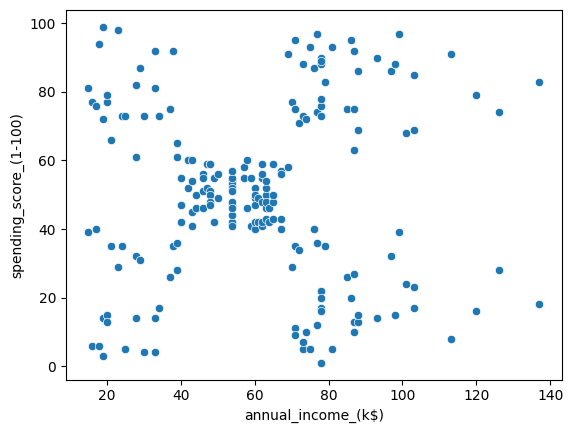

In [2]:
print(df.isna().sum()); print('Duplicates:',df.duplicated().sum())
df=df.drop_duplicates().copy(); df.columns=[c.strip().lower().replace(' ','_') for c in df.columns]
X=df[['annual_income_(k$)','spending_score_(1-100)']]; scaled=StandardScaler().fit_transform(X)
sns.scatterplot(x=X.iloc[:,0],y=X.iloc[:,1]); plt.show()

## Transform and Data Mining
Standardize the features and compare candidate cluster counts using inertia and silhouette score. Fit the selected K-means model.

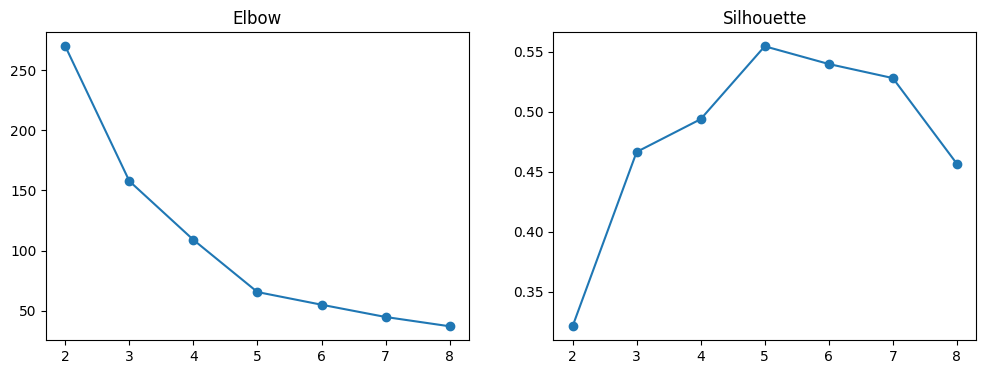

Silhouette: 0.555


In [3]:
inertia=[]; sil=[]
for k in range(2,9):
    km=KMeans(n_clusters=k,n_init=20,random_state=42).fit(scaled); inertia.append(km.inertia_); sil.append(silhouette_score(scaled,km.labels_))
fig,ax=plt.subplots(1,2,figsize=(12,4)); ax[0].plot(range(2,9),inertia,'o-'); ax[0].set_title('Elbow'); ax[1].plot(range(2,9),sil,'o-'); ax[1].set_title('Silhouette'); plt.show()
k=5; model=KMeans(n_clusters=k,n_init=20,random_state=42); df['segment']=model.fit_predict(scaled); print('Silhouette:',round(silhouette_score(scaled,df['segment']),3))

## Interpret and Evaluate Knowledge
Summarize each segment and visualize the discovered groups. Segment names are descriptive hypotheses, not permanent customer identities.

annual_income_(k$)        spending_score_(1-100)       
                     count   mean                  count   mean
segment                                                        
0                       81  55.30                     81  49.52
1                       39  86.54                     39  82.13
2                       22  25.73                     22  79.36
3                       35  88.20                     35  17.11
4                       23  26.30                     23  20.91

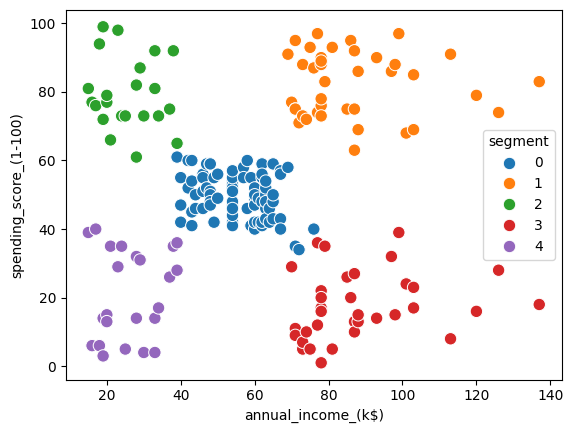

In [4]:
display(df.groupby('segment')[['annual_income_(k$)','spending_score_(1-100)']].agg(['count','mean']).round(2))
sns.scatterplot(data=df,x='annual_income_(k$)',y='spending_score_(1-100)',hue='segment',palette='tab10',s=80); plt.show()

## Limitations
K-means depends on scaling and the chosen K, assumes relatively compact clusters, and ignores purchase recency and frequency. Future work should add transaction-level RFM features, test stability over time, and validate whether segment-specific campaigns improve outcomes.

## Expanded Select and Preprocess

KDD starts by defining the knowledge-discovery objective and selecting variables that can support it. CustomerID is an identifier, not a behavioral feature, so it is excluded from clustering. Gender and Age are retained for post-hoc profiling rather than used to define the segments.

In [5]:
print(df.info())
print("Missing values:", df.isna().sum().to_dict())
print("Duplicate rows:", df.duplicated().sum())
numeric_profile = df[["age","annual_income_(k$)","spending_score_(1-100)"]].describe().T
display(numeric_profile)
print("Selection rationale: income and spending score directly represent the intended marketing segmentation question.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   customerid              200 non-null    int64 
 1   gender                  200 non-null    object
 2   age                     200 non-null    int64 
 3   annual_income_(k$)      200 non-null    int64 
 4   spending_score_(1-100)  200 non-null    int64 
 5   segment                 200 non-null    int32 
dtypes: int32(1), int64(4), object(1)
memory usage: 8.7+ KB
None
Missing values: {'customerid': 0, 'gender': 0, 'age': 0, 'annual_income_(k$)': 0, 'spending_score_(1-100)': 0, 'segment': 0}
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,200.0,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
annual_income_(k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.0,137.0
spending_score_(1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.0,99.0


Selection rationale: income and spending score directly represent the intended marketing segmentation question.


## Transform: Scaling and Outlier Review

K-means uses distance, so variables must be placed on comparable scales. We inspect ranges before standardization and use the standardized values for mining.

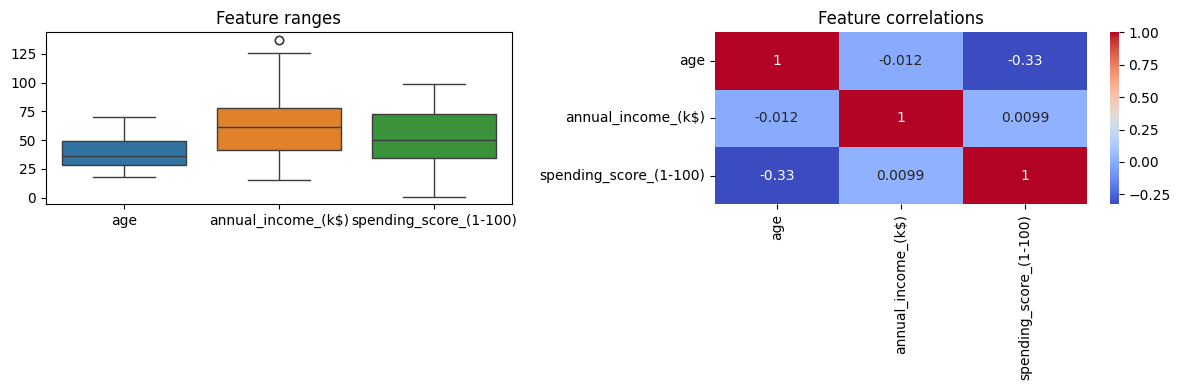

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=df[["age","annual_income_(k$)","spending_score_(1-100)"]],ax=ax[0]); ax[0].set_title("Feature ranges")
sns.heatmap(df[["age","annual_income_(k$)","spending_score_(1-100)"]].corr(),annot=True,cmap="coolwarm",ax=ax[1]); ax[1].set_title("Feature correlations")
plt.tight_layout(); plt.show()

## Data Mining: Candidate Algorithms

K-means is appropriate as a transparent baseline for numeric segmentation. We use elbow and silhouette diagnostics to select K, then examine whether the resulting groups are interpretable and sufficiently separated.

In [7]:
from sklearn.cluster import AgglomerativeClustering
for k_candidate in [4,5,6]:
    labels = KMeans(n_clusters=k_candidate,n_init=20,random_state=42).fit_predict(scaled)
    print("K-means", k_candidate, "silhouette", round(silhouette_score(scaled,labels),3))
for k_candidate in [4,5,6]:
    labels = AgglomerativeClustering(n_clusters=k_candidate).fit_predict(scaled)
    print("Agglomerative", k_candidate, "silhouette", round(silhouette_score(scaled,labels),3))

K-means 4 silhouette 0.494
K-means 5 silhouette 0.555
K-means 6 silhouette 0.54
Agglomerative 4 silhouette 0.493
Agglomerative 5 silhouette 0.554
Agglomerative 6 silhouette 0.539


## Interpret, Profile, and Evaluate

A cluster is useful only when it is understandable and stable enough to support an action. We profile each segment by age, income, spending score, and gender, then use the silhouette score as one quantitative separation measure.

In [8]:
profile = df.groupby("segment").agg(
    customers=("segment","size"),
    mean_age=("age","mean"),
    mean_income=("annual_income_(k$)","mean"),
    mean_spending=("spending_score_(1-100)","mean"),
    female_share=("gender",lambda s:(s.str.lower()=="female").mean())
).round(2)
display(profile)
print("Operational interpretation should be based on income/spending patterns; demographic differences are for descriptive analysis and should not be used for unfair targeting.")

,customers,mean_age,mean_income,mean_spending,female_share
segment,,,,,
0,81,42.72,55.30,49.52,0.59
1,39,32.69,86.54,82.13,0.54
2,22,25.27,25.73,79.36,0.59
3,35,41.11,88.20,17.11,0.46
4,23,45.22,26.30,20.91,0.61


Operational interpretation should be based on income/spending patterns; demographic differences are for descriptive analysis and should not be used for unfair targeting.


## Stability Check

Because clustering can depend on initialization and sampling, we compare assignments across multiple random seeds using adjusted Rand index. A low stability score would mean the chosen segments should not be operationalized without further data.

In [9]:
from sklearn.metrics import adjusted_rand_score
label_runs=[]
for seed in [1,7,21,42,99]:
    label_runs.append(KMeans(n_clusters=5,n_init=20,random_state=seed).fit_predict(scaled))
for i in range(1,len(label_runs)):
    print("Seed", [1,7,21,42,99][i], "ARI vs seed 1:", round(adjusted_rand_score(label_runs[0],label_runs[i]),3))

Seed 7 ARI vs seed 1: 1.0
Seed 21 ARI vs seed 1: 1.0
Seed 42 ARI vs seed 1: 1.0
Seed 99 ARI vs seed 1: 1.0


## KDD Knowledge Output and Next Action

The final knowledge product is a labeled customer-segment table, a segment profile table, and a visualization. A responsible next step is to test segment-specific marketing hypotheses through controlled experiments. The clusters should not be treated as permanent identities, and protected characteristics should not be used to deny services or opportunities.

## Limitations

The dataset is small, cross-sectional, and lacks recency, frequency, monetary value, product category, and campaign response. K-means assumes compact geometry and depends on K and scaling. Future KDD iterations should add transaction-level features, test temporal stability, compare clustering methods, and validate business lift.